# Two point reflectors: Fabry–Pérot

The NumPy reference solver includes all scattering orders in a static scalar
fiber. Here we compare its complex fields with the closed two-mirror formula.
There are no Rayleigh samples in this example, so the analytic reference is
independent of their discretization. The right port is matched.

Run with Python, NumPy, Matplotlib, Jupyter and PyRayleigh installed, or from
this source checkout. All cells can be run in order. Section attenuation is
declared as **background power loss in 1/m**, not total measured attenuation.
We use float64 / complex128 throughout.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

repo = Path.cwd()
if repo.name == 'examples':
    repo = repo.parent
if (repo/'src'/'pyrayleigh').is_dir():
    sys.path.insert(0, str(repo/'src'))

import pyrayleigh
from pyrayleigh import (Fiber, FiberState, Field, FieldTerm, GuideOptics,
                       Probe, Section, SpatialProfile, lossless_reflector)
from pyrayleigh.constants import SPEED_OF_LIGHT as c
from pyrayleigh import compute_response

%matplotlib inline
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
print('PyRayleigh', pyrayleigh.__version__, '| NumPy', np.__version__)
print('Backend: NumPy | parameter precision: float64 | fields: complex128')

PyRayleigh 0.1.0.dev0 | NumPy 2.5.4
Backend: NumPy | parameter precision: float64 | fields: complex128


For a uniform guide, the one-way factor over material length $d$ is

$$p(d)=e^{-\alpha d/2}e^{-i\beta_0 d}e^{-i\Delta\beta d},\quad
\beta_0=2\pi n\nu_0/c,\quad \Delta\beta=2\pi n_g(\nu-\nu_0)/c.$$

The two points are at $a$ and $b$. Write $p_0=p(a)$, $p_c=p(b-a)$,
$p_e=p(L-b)$ and $D=1-r_{A,R}r_{B,L}p_c^2$. The analytic fields are

$$r=p_0^2\left(r_{A,L}+\frac{t_{A,RL}t_{A,LR}r_{B,L}p_c^2}{D}\right),
\qquad t=\frac{p_0t_{A,LR}p_ct_{B,LR}p_e}{D}.$$

These functions use lengths, coefficients and the uniform guide equation
directly. They do not call `OpticalPath`, `TwoPort` or `star`.

In [2]:
n = ng = 1.46
nu0 = c/1550e-9
L, a = .01, .001
b = a + (1000+.25)*1550e-9/n
frequency = nu0 + np.linspace(-6e9, 6e9, 3001)
probe = Probe(frequency)
guide = GuideOptics(nu0, n, ng, gvd=0.)
beta0 = 2*np.pi*n*nu0/c
delta_beta = 2*np.pi*ng*(frequency-nu0)/c

def p(d, alpha, extra_length=0.):
    # Extra optical length changes phase, while loss stays on material length.
    return (np.exp(-alpha*d/2)*np.exp(-1j*beta0*(d+extra_length))
            * np.exp(-1j*delta_beta*(d+extra_length)))

def analytic(A, B, alpha, extra=(0., 0., 0.)):
    p0, pc, pe = p(a, alpha, extra[0]), p(b-a, alpha, extra[1]), p(L-b, alpha, extra[2])
    denominator = 1.-A.r_right*B.r_left*pc**2
    r = p0**2*(A.r_left + A.t_right_to_left*A.t_left_to_right*B.r_left*pc**2/denominator)
    t = p0*A.t_left_to_right*pc*B.t_left_to_right*pe/denominator
    return r, t, denominator

def model(RA, RB, alpha):
    A, B = lossless_reflector(a, RA), lossless_reflector(b, RB)
    section = Section(0., L, guide, attenuation=alpha, rayleigh_coefficient=0.)
    fiber = Fiber('fp', L, 293.15, nu0-1e12, nu0+1e12, (section,), elements=(A, B))
    return fiber, A, B

field_atol, field_rtol, energy_atol = 2e-10, 2e-10, 3e-12
print(f'L={L:.6g} m, a={a:.6g} m, b={b:.12g} m, n=ng={n}')
print(f'nu0={nu0:.12g} Hz, {frequency.size} samples, step={frequency[1]-frequency[0]:.6g} Hz')
print(f'Field atol={field_atol:g}, rtol={field_rtol:g}; energy atol={energy_atol:g}')

L=0.01 m, a=0.001 m, b=0.00206190924658 m, n=ng=1.46
nu0=1.93414489032e+14 Hz, 3001 samples, step=4e+06 Hz
Field atol=2e-10, rtol=2e-10; energy atol=3e-12


## Weak and strong reflectors, with and without loss

The complex-field comparison includes phase. We also report the relative
L2 error of each field. For a lossless cavity, R+T must be one; with background
loss it must not exceed one. A small cascade-denominator cutoff only rejects
ill-conditioned arithmetic: it does not guarantee accuracy near every
high-Q resonance. These tolerances apply to the parameters and grid below.

In [3]:
cases = [('weak', .04, .09, 0.), ('strong', .99, .99, 0.), ('lossy', .9, .9, 2.)]
results = {}
print('case       max|dr|       max|dt|       rel L2(r)     rel L2(t)     min|D|       max(R+T)')
for name, RA, RB, alpha in cases:
    fiber, A, B = model(RA, RB, alpha)
    actual = compute_response(fiber, probe, method='exact', loss_convention='background')
    r, t, denominator = analytic(A, B, alpha)
    np.testing.assert_allclose(actual.reflection, r, atol=field_atol, rtol=field_rtol)
    np.testing.assert_allclose(actual.transmission, t, atol=field_atol, rtol=field_rtol)
    energy = abs(actual.reflection)**2+abs(actual.transmission)**2
    if alpha == 0.:
        np.testing.assert_allclose(energy, 1., atol=energy_atol, rtol=0.)
    else:
        assert np.all(energy <= 1.+energy_atol)
    dr, dt = actual.reflection-r, actual.transmission-t
    relative_r = np.linalg.norm(dr)/np.linalg.norm(r)
    relative_t = np.linalg.norm(dt)/np.linalg.norm(t)
    print(f'{name:8} {max(abs(dr)):.3e}    {max(abs(dt)):.3e}    {relative_r:.3e}    '
          f'{relative_t:.3e}    {min(abs(denominator)):.3e}    {max(energy):.12f}')
    results[name] = actual, r, t, energy

case       max|dr|       max|dt|       rel L2(r)     rel L2(t)     min|D|       max(R+T)
weak     2.012e-16    8.006e-16    5.337e-16    1.751e-16    9.400e-01    1.000000000000
strong   2.083e-14    2.066e-14    1.158e-15    5.641e-15    1.000e-02    1.000000000000
lossy    4.025e-15    3.848e-15    8.668e-16    1.154e-15    1.019e-01    0.992302713022


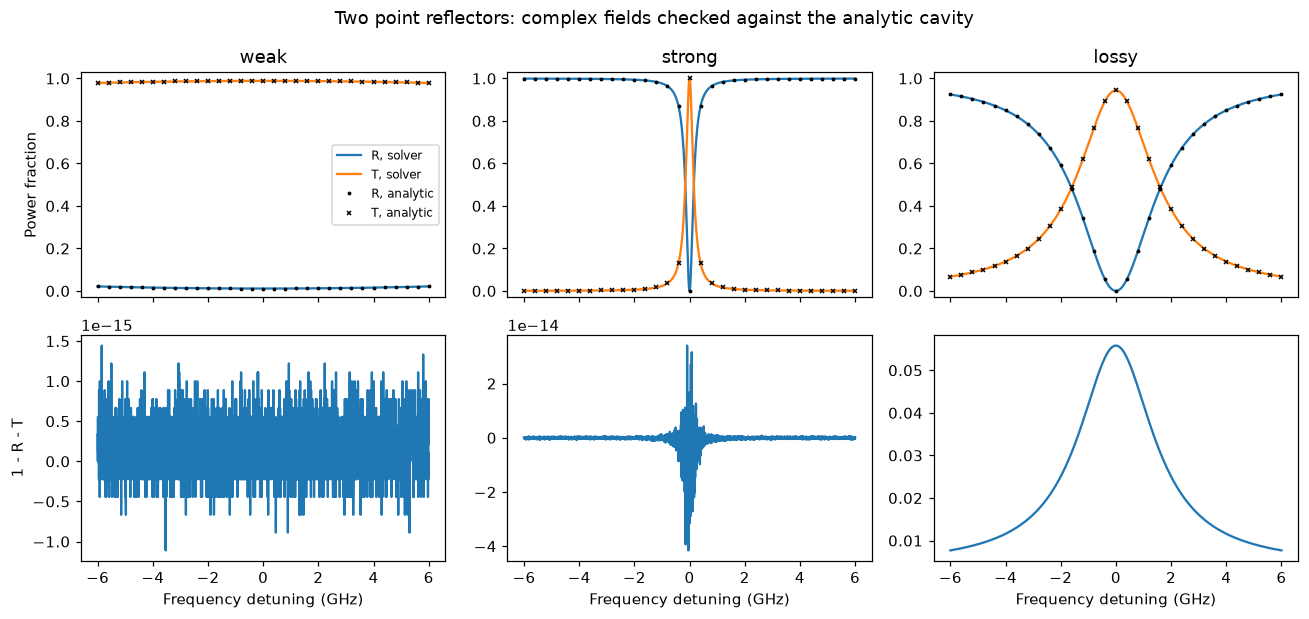

In [4]:
detuning = (frequency-nu0)/1e9
fig, axes = plt.subplots(2, 3, figsize=(12, 5.7), sharex=True)
for column, (name, _, _, _) in enumerate(cases):
    actual, r, t, energy = results[name]
    ax = axes[0, column]
    ax.plot(detuning, abs(actual.reflection)**2, label='R, solver')
    ax.plot(detuning, abs(actual.transmission)**2, label='T, solver')
    ax.plot(detuning[::100], abs(r[::100])**2, 'k.', ms=3, label='R, analytic')
    ax.plot(detuning[::100], abs(t[::100])**2, 'kx', ms=3, label='T, analytic')
    ax.set(title=name, ylim=(-.03, 1.03))
    axes[1, column].plot(detuning, 1.-energy)
    axes[1, column].set_xlabel('Frequency detuning (GHz)')
axes[0, 0].set_ylabel('Power fraction')
axes[1, 0].set_ylabel('1 - R - T')
axes[0, 0].legend(fontsize=8)
fig.suptitle('Two point reflectors: complex fields checked against the analytic cavity')
fig.tight_layout()
plt.show()

## Local strain on the physical legs

Use the same two points and change only the static fiber state. This example
sets n=ng and zero GVD, with equal phase and group strain factors. A constant
strain epsilon over overlap length h adds `strain_factor * epsilon * h` to
that leg's phase length. Loss is still integrated over material position.

We compare the full cavity response for strain before A, between A and B,
and beyond B. The reflection cannot depend on strain beyond B in this
point-only model, but the transmitted phase does change there.

In [5]:
fiber, A, B = model(.9, .9, 0.)
epsilon = 1e-6
regions = {'before A': (.0002, .0008),
           'between A and B': (a+.2*(b-a), a+.8*(b-a)),
           'beyond B': (b+.001, b+.002)}
baseline = compute_response(fiber, probe, method='exact', loss_convention='background')
changed = {}
for name, (low, high) in regions.items():
    profile = SpatialProfile([low, high], [epsilon, epsilon])
    state = FiberState(axial_strain=Field((FieldTerm(profile),)))
    actual = compute_response(fiber, probe, state, method='exact', loss_convention='background')
    extra = tuple(guide.strain_phase_factor*epsilon*max(0., min(end, high)-max(start, low))
                  for start, end in ((0., a), (a, b), (b, L)))
    r, t, _ = analytic(A, B, 0., extra)
    np.testing.assert_allclose(actual.reflection, r, atol=field_atol, rtol=field_rtol)
    np.testing.assert_allclose(actual.transmission, t, atol=field_atol, rtol=field_rtol)
    changed[name] = actual
    print(f'{name:18} max|dr|={max(abs(actual.reflection-r)):.3e}, '
          f'max|dt|={max(abs(actual.transmission-t)):.3e}')

np.testing.assert_array_equal(changed['beyond B'].reflection, baseline.reflection)
assert max(abs(changed['beyond B'].transmission-baseline.transmission)) > 1e-4
print('Strain beyond B leaves reflection unchanged; transmission phase changes.')

before A           max|dr|=2.515e-15, max|dt|=2.410e-15
between A and B    max|dr|=2.180e-15, max|dt|=2.384e-15
beyond B           max|dr|=2.398e-15, max|dt|=2.248e-15
Strain beyond B leaves reflection unchanged; transmission phase changes.


The first repeated point path is $0\to b\to a\to b\to0$. Its physical
crossing counts are 2 before A, 4 inside the cavity and 0 beyond B. These
counts refer to this individual path, not the phase of the full multipath
sum. We check that path through the existing path evaluator separately.
Its apparent position $2b-a$ is not a propagation endpoint.

In [6]:
from pyrayleigh import point_reflection_paths, multiple_point_response

paths = point_reflection_paths(fiber, max_order=2)
assert tuple(path for path in paths if len(path) == 3) == ((1, 0, 1),)
reference_ghost = multiple_point_response(fiber, frequency, max_order=2)
beta = beta0+delta_beta
counts = (2, 4, 0)
for (name, (low, high)), crossings in zip(regions.items(), counts):
    profile = SpatialProfile([low, high], [epsilon, epsilon])
    state = FiberState(axial_strain=Field((FieldTerm(profile),)))
    actual_ghost = multiple_point_response(fiber, frequency, state, max_order=2)
    phase_change = -crossings*beta*guide.strain_phase_factor*epsilon*(high-low)
    np.testing.assert_allclose(actual_ghost/reference_ghost, np.exp(1j*phase_change), atol=2e-10, rtol=2e-10)
    print(f'{name:18} crossings={crossings}, phase change at nu0={phase_change[len(frequency)//2]:.6g} rad')

before A           crossings=2, phase change at nu0=-0.00553958 rad
between A and B    crossings=4, phase change at nu0=-0.0117651 rad
beyond B           crossings=0, phase change at nu0=0 rad


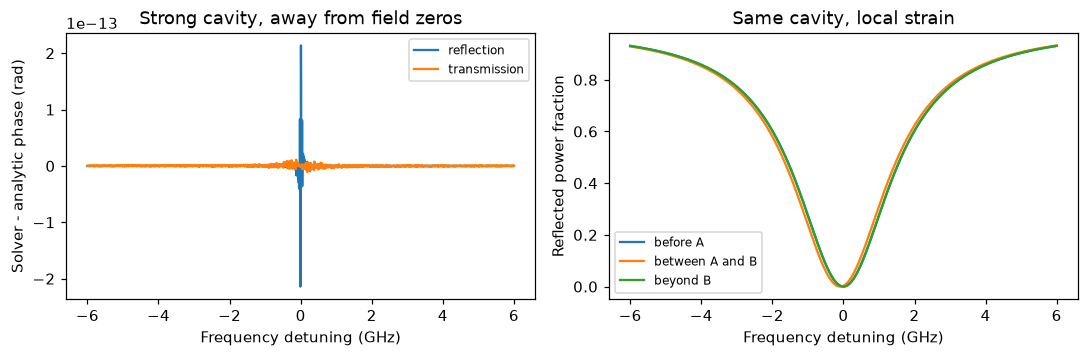

In [7]:
actual, r, t, _ = results['strong']
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for field, reference, label in ((actual.reflection, r, 'reflection'), (actual.transmission, t, 'transmission')):
    # Reflection phase is undefined at an exact zero.
    mask = abs(reference) > 1e-6
    error = np.angle(field[mask]*np.conj(reference[mask]))
    axes[0].plot(detuning[mask], error, label=label)
for name, actual in changed.items():
    axes[1].plot(detuning, abs(actual.reflection)**2, label=name)
axes[0].set(xlabel='Frequency detuning (GHz)', ylabel='Solver - analytic phase (rad)', title='Strong cavity, away from field zeros')
axes[1].set(xlabel='Frequency detuning (GHz)', ylabel='Reflected power fraction', title='Same cavity, local strain')
for ax in axes:
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

This checks a finite scalar static cavity. It does not validate Rayleigh-grid
convergence, distributed Bragg gratings, time-dependent propagation, multicore
coupling or a JAX implementation. The all-orders reference is selected through
`compute_response(..., method="exact", loss_convention="background")`.
Omitting `method` keeps the earlier truncated model and its `max_order` behavior.
An explicit `max_order` is rejected for the exact method.